# Training YOLOv8 — Final Project Oprec PENSHIP

Notebook dasar untuk melatih model deteksi `bottle`, `laptop`, dan `pencil` di Google Colab.
Jalankan cell dari atas ke bawah (**Shift + Enter**). Kode ini sengaja dibuat dasar dan **wajib dikembangkan oleh peserta** (lihat bagian Pengembangan kode di guidebook).

## 1. Aktifkan GPU

Menu **Runtime → Change runtime type → T4 GPU → Save**, lalu jalankan cell di bawah.
Apabila muncul tabel berisi nama GPU (misalnya Tesla T4), GPU sudah aktif.

In [ ]:
!nvidia-smi

Sat Oct 24 14:29:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install library

In [ ]:
%pip install -q "ultralytics>=8.3.0" "roboflow>=1.1.0"

## 3. API key Roboflow

Simpan API key di **Colab Secrets**, jangan diketik di notebook (notebook ini ikut dikumpulkan):

1. Ambil API key di https://app.roboflow.com/settings/api
2. Klik ikon kunci (**Secrets**) di panel kiri Colab → **Add new secret**.
3. Name: `ROBOFLOW_API_KEY`, Value: API key Roboflow, lalu aktifkan **Notebook access**.

Apabila secret tidak ditemukan, cell di bawah akan meminta API key lewat kotak input tersembunyi.

In [ ]:
import os

if not os.environ.get("ROBOFLOW_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        from getpass import getpass
        os.environ["ROBOFLOW_API_KEY"] = getpass("Roboflow API key: ")

print("API key is set.")

API key is set.


## 4. Konfigurasi

Workspace, project, dan nomor versi tertera pada URL dataset: `app.roboflow.com/<workspace>/<project>/<version>`,
atau di potongan kode saat **Download Dataset → YOLOv8 → Show download code**.

In [ ]:
# Dataset (Roboflow)
ROBOFLOW_WORKSPACE = "abimanyus-workspace-lempe"  # from the dataset URL
ROBOFLOW_PROJECT = "bottle-laptop-pencil"      # from the dataset URL
ROBOFLOW_VERSION = 8                  # dataset version number on Roboflow
DATASET_DIR = "dataset"                # download destination folder

# Training
MODEL = "yolov8n.pt"  # options: yolov8n.pt or yolov8s.pt
EPOCHS = 100
IMGSZ = 640           # must stay 640, do not change
BATCH = 16            # lower to 8 on out-of-memory errors
SEED = 0

## 5. Download dataset

Apabila folder `dataset/` sudah berisi `data.yaml`, download dilewati.

In [ ]:
from pathlib import Path

data_yaml = Path(DATASET_DIR) / "data.yaml"
if data_yaml.exists():
    print(f"Dataset already exists, skipping download: {data_yaml}")
else:
    from roboflow import Roboflow

    rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
    version = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT).version(ROBOFLOW_VERSION)
    dataset = version.download("yolov8", location=DATASET_DIR)
    data_yaml = Path(dataset.location) / "data.yaml"

print(data_yaml.read_text())

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 93.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to dataset in yolov8:: 100%|██████████| 153/153 [00:00<00:00, 2031.34it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
names:
- bottle
- laptop
- pencil
nc: 3
roboflow:
  license: CC BY 4.0
  project: bottle-laptop-pencil
  url: https://universe.roboflow.com/abimanyus-workspace-lempe/bottle-laptop-pencil/dataset/8
  version: 8
  workspace: abimanyus-workspace-lempe
test: ../test/images
train: ../train/images
val: ../valid/images



## 6. Training

Dengan T4 GPU dan beberapa ratus foto, 50 epoch biasanya selesai dalam hitungan menit sampai sekitar setengah jam.

In [ ]:
from ultralytics import YOLO

model = YOLO(MODEL)  # pretrained weights are downloaded automatically
model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    seed=SEED,
    patience=80,
    hsv_v=0.5,
)

save_dir = Path(model.trainer.save_dir)
best_path = save_dir / "weights" / "best.pt"
print(f"Training output: {save_dir}")
print(f"Best model     : {best_path}")

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer

## 7. Lihat grafik hasil training

results.png


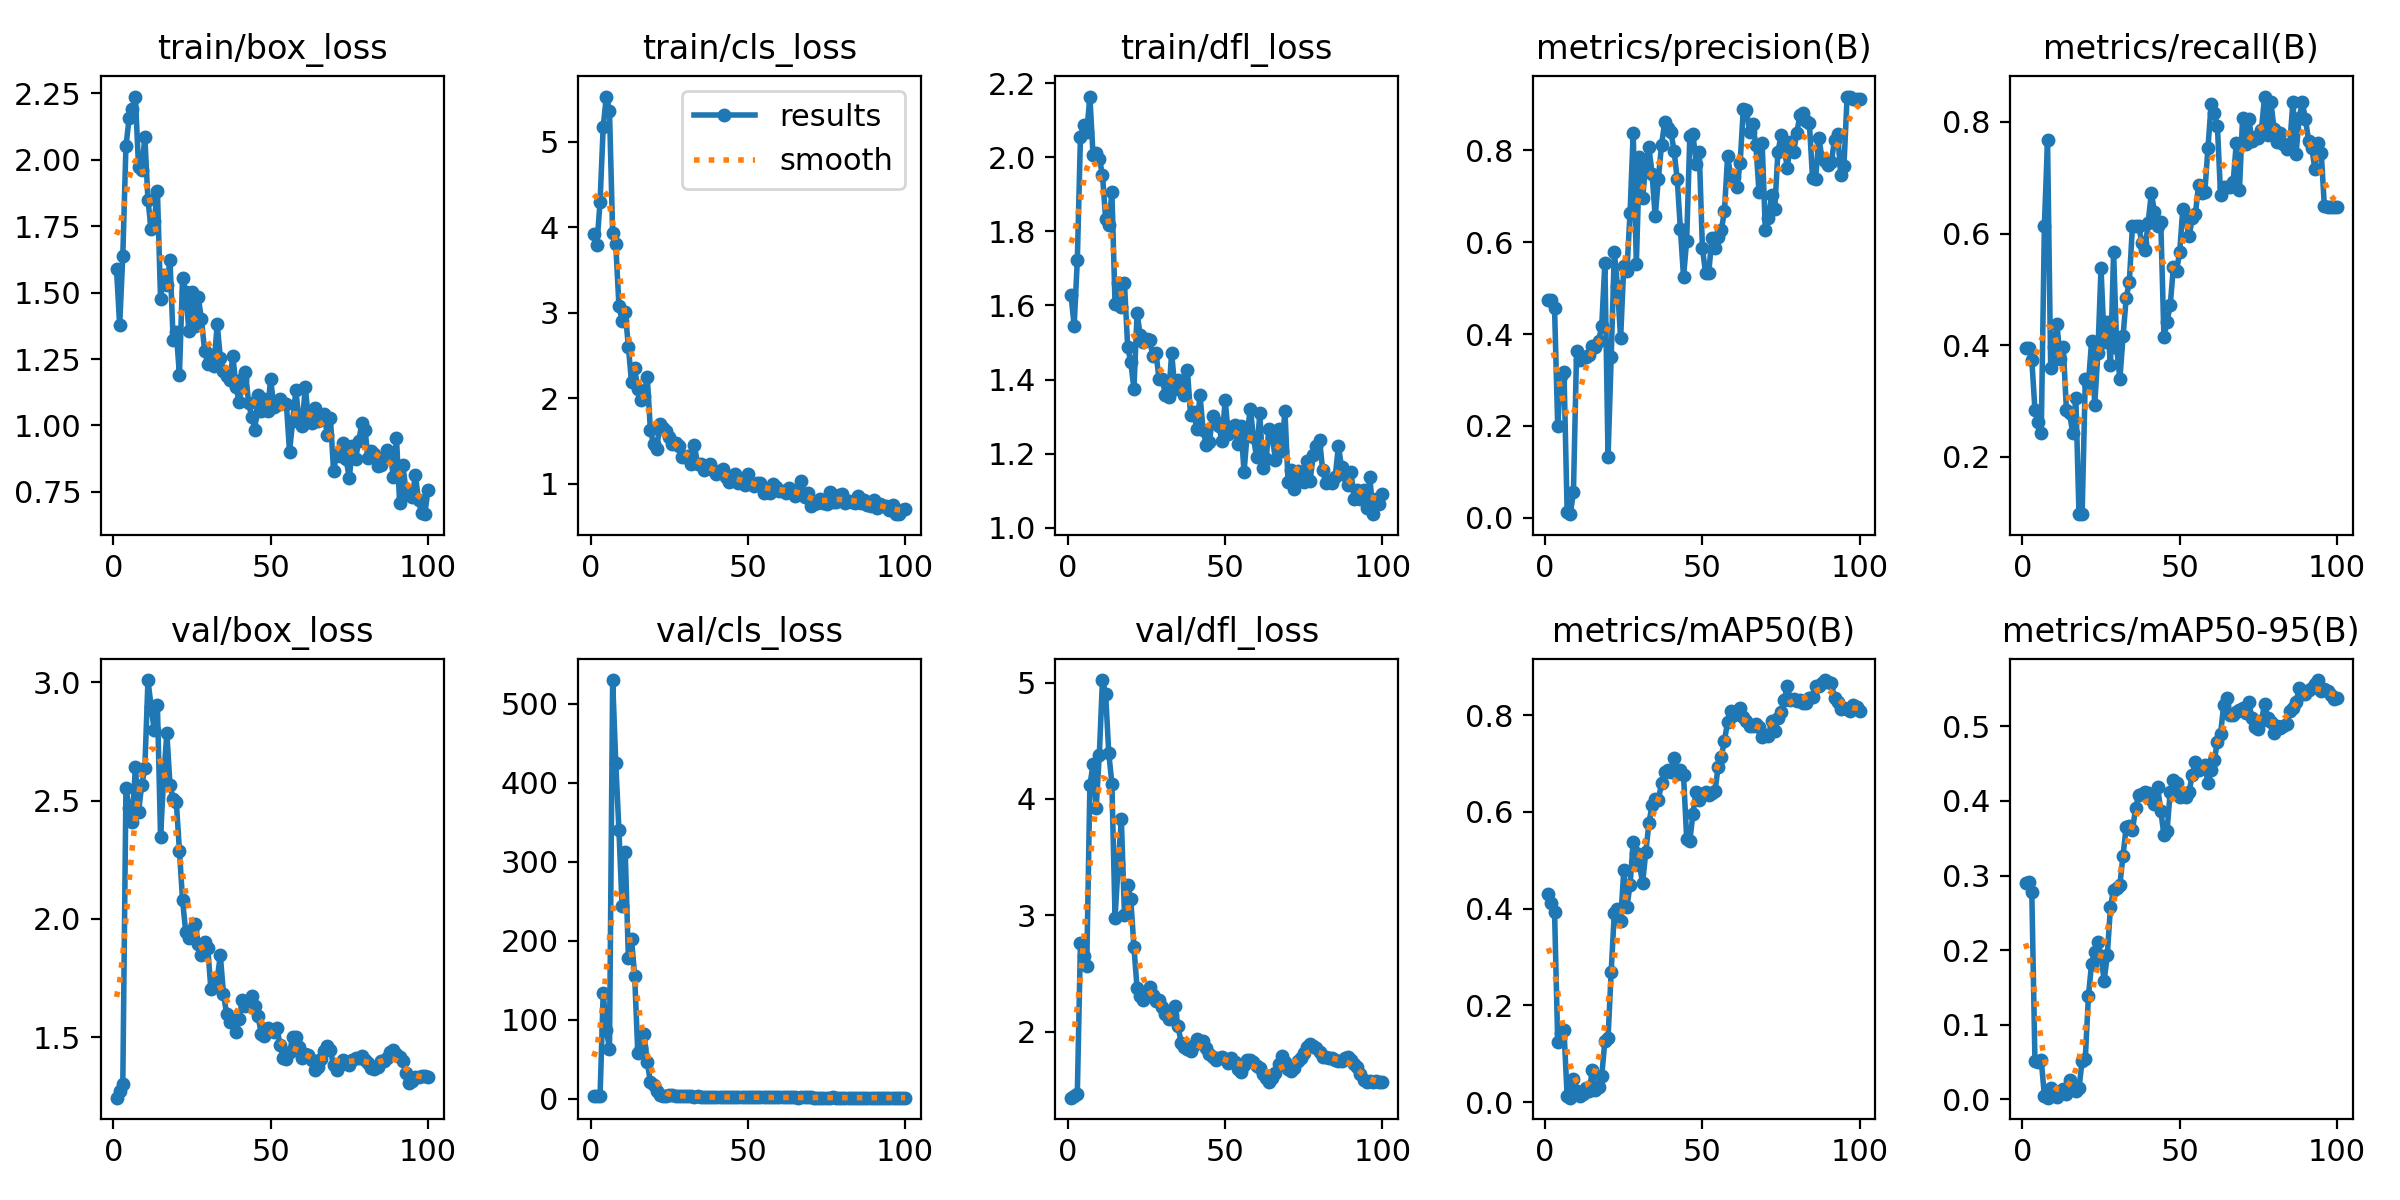

confusion_matrix.png


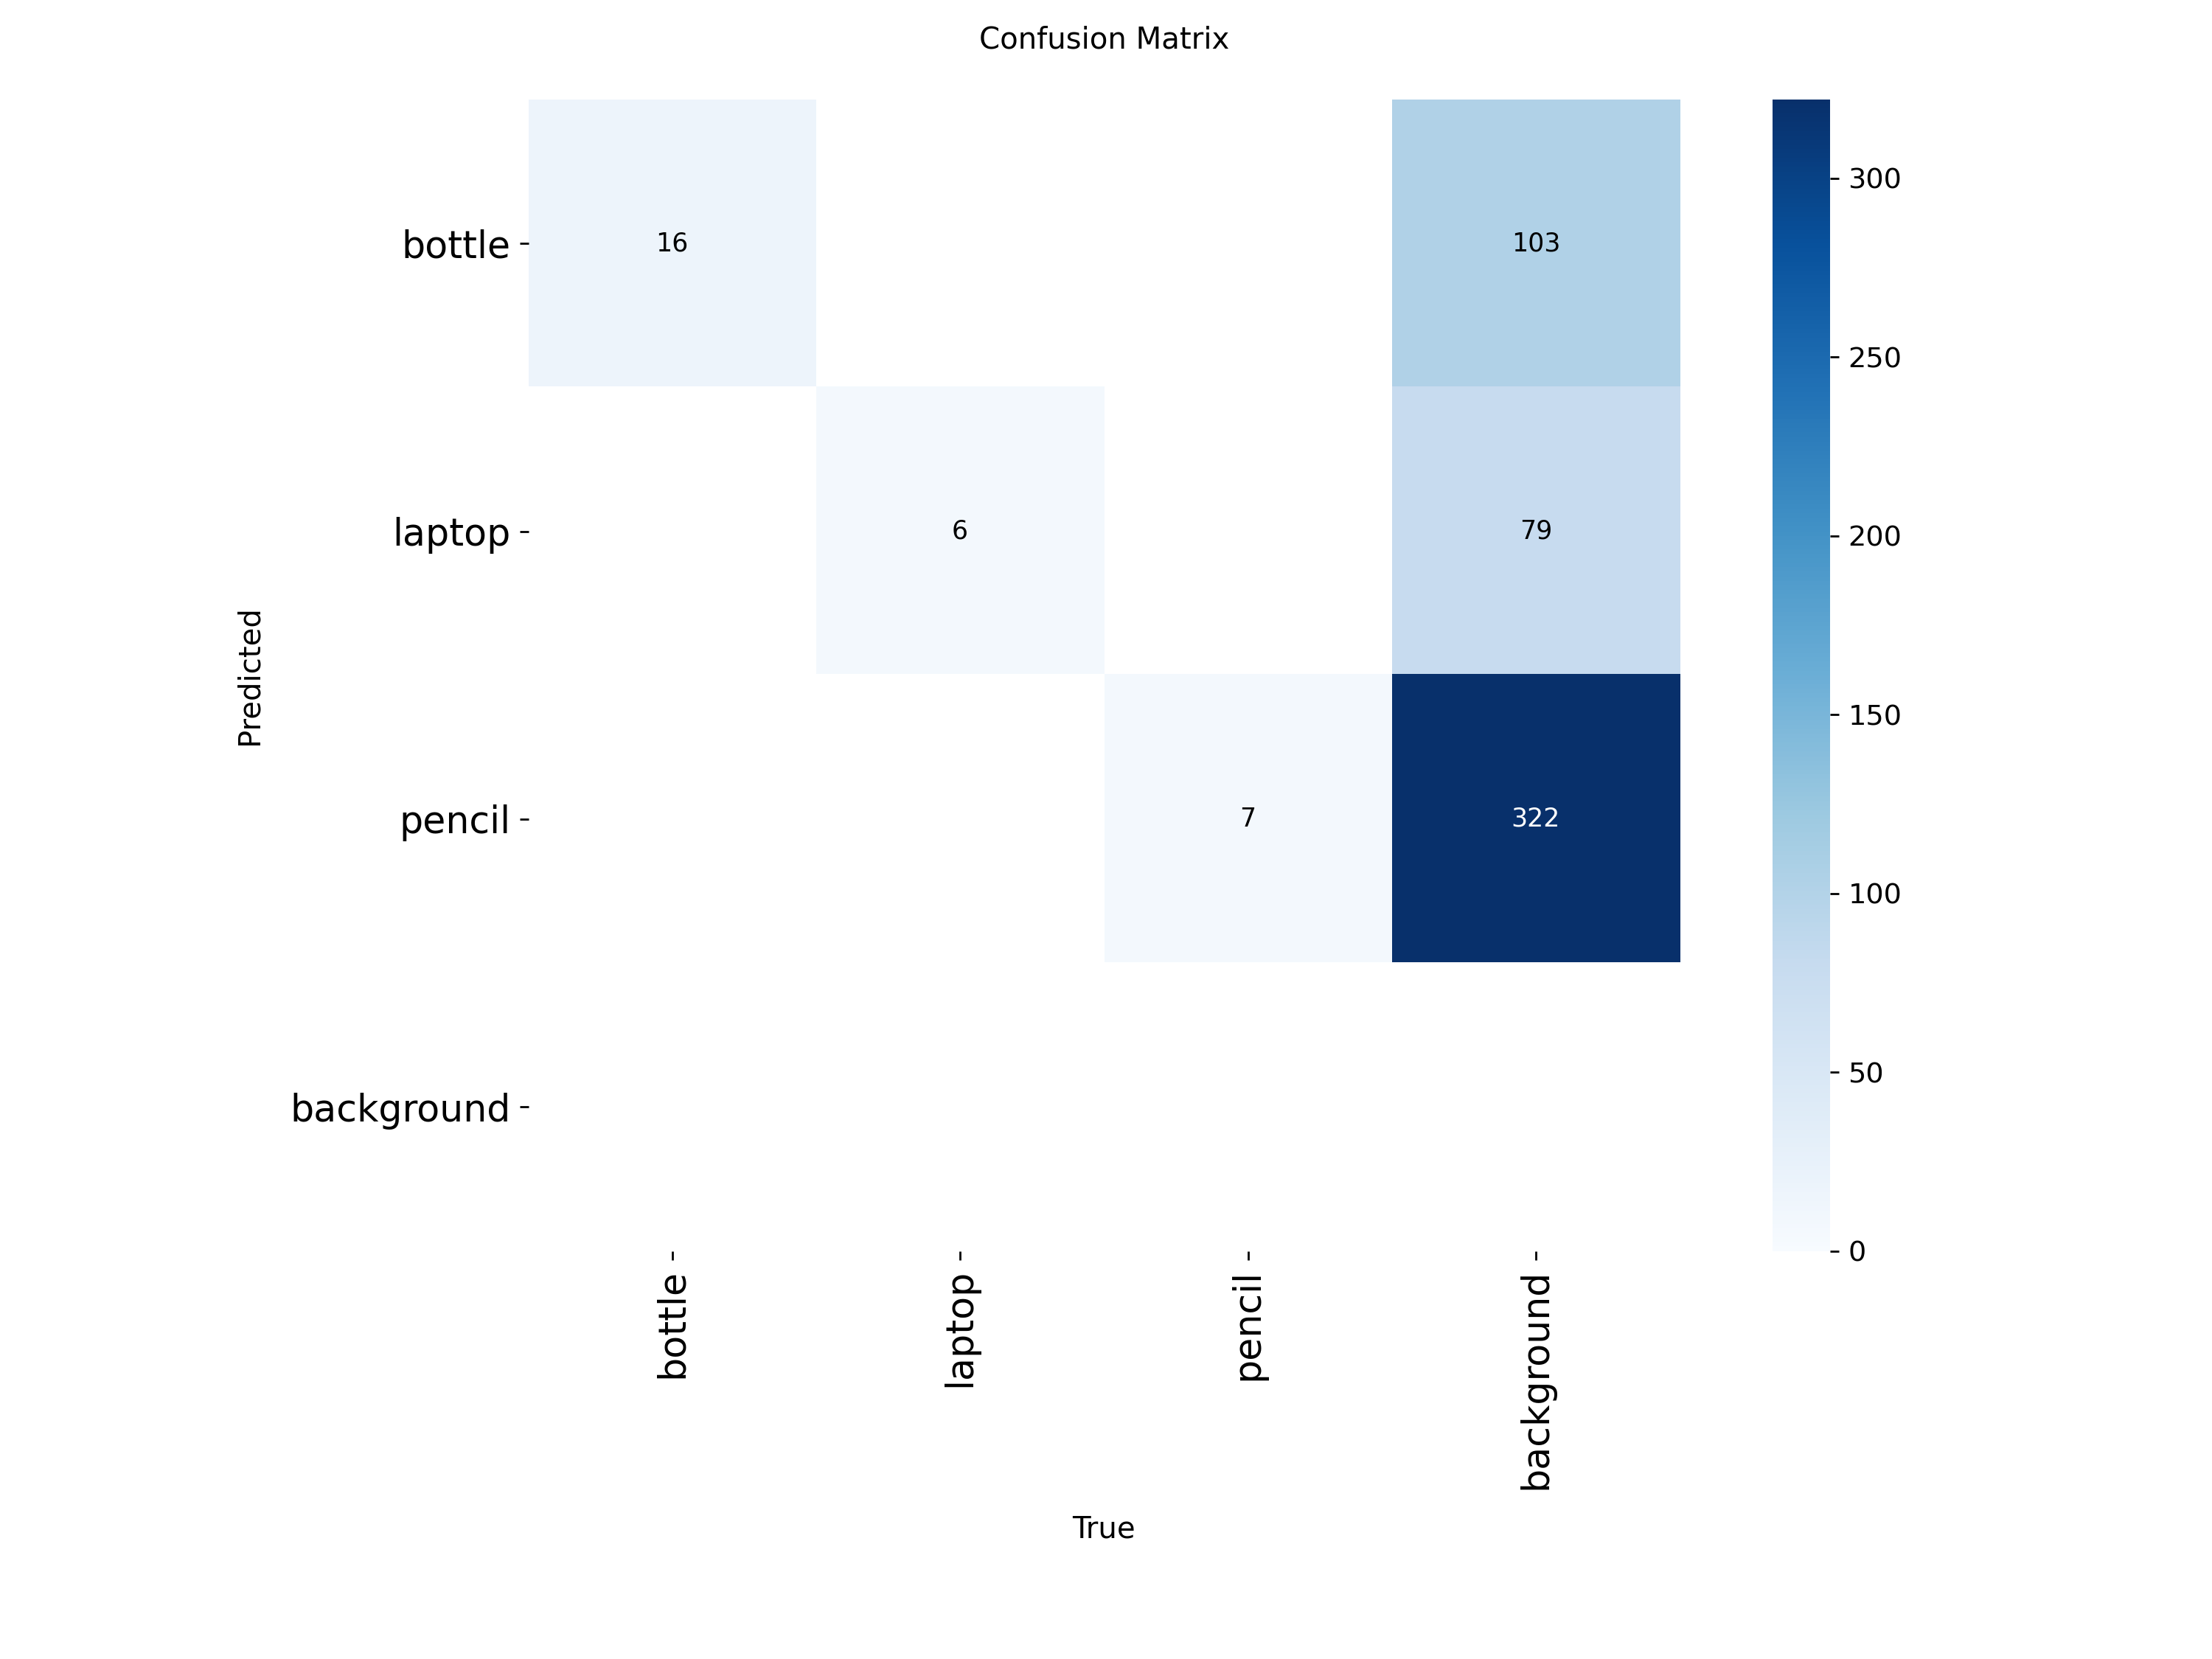

In [ ]:
from IPython.display import Image, display

for name in ["results.png", "confusion_matrix.png"]:
    path = save_dir / name
    if path.exists():
        print(name)
        display(Image(filename=str(path), width=900))

## 8. Evaluasi model terbaik di data validation

In [ ]:
best_model = YOLO(str(best_path))
metrics = best_model.val(data=str(data_yaml), imgsz=IMGSZ)
print(f"mAP50-95: {metrics.box.map:.3f} | mAP50: {metrics.box.map50:.3f}")

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1733.3±652.8 MB/s, size: 47.6 KB)
val: Scanning /content/dataset/valid/labels.cache... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.6it/s 0.3s
                   all         15         29      0.745      0.762      0.814      0.567
                bottle          6         16      0.747      0.738      0.775      0.512
                laptop          6          6      0.767      0.833      0.931      0.731
                pencil          5          7      0.721      0.714      0.736      0.457
Speed: 0.4ms preprocess, 7.0ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val
mAP50-95: 0.567 | m

## 9. Coba prediksi beberapa foto validation


0: 640x640 (no detections), 10.2ms
1: 640x640 3 bottles, 10.2ms
2: 640x640 3 bottles, 10.2ms
3: 640x640 4 bottles, 10.2ms
Speed: 1.1ms preprocess, 10.2ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Prediction images saved to: /content/runs/detect/predict


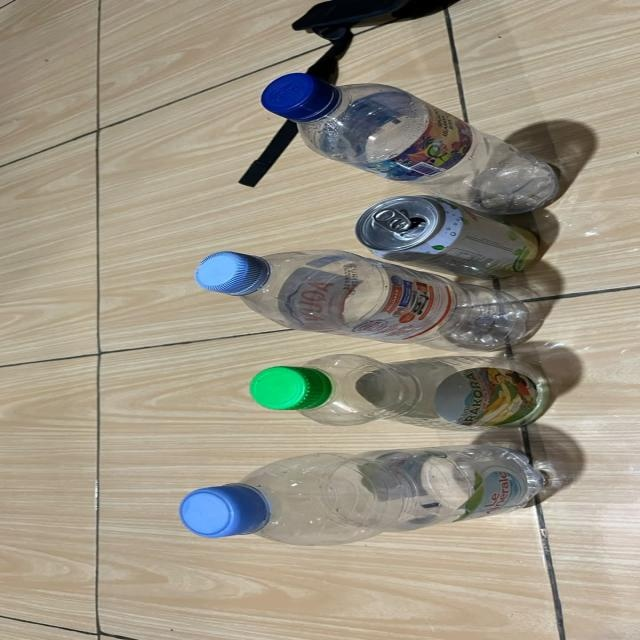

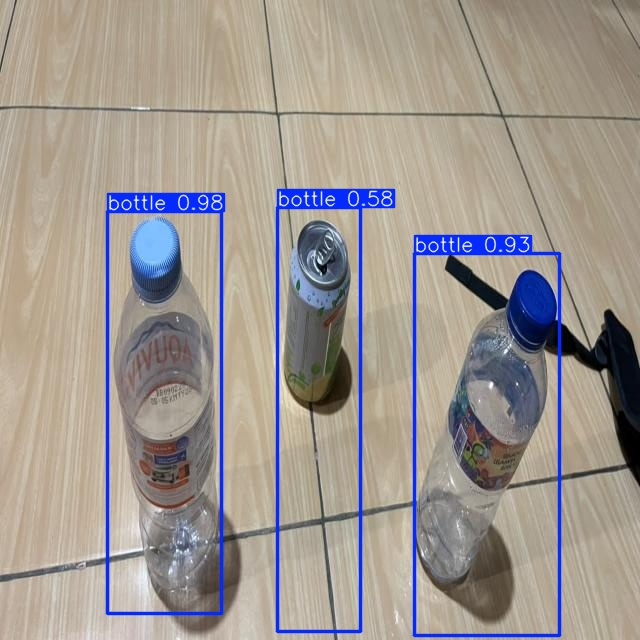

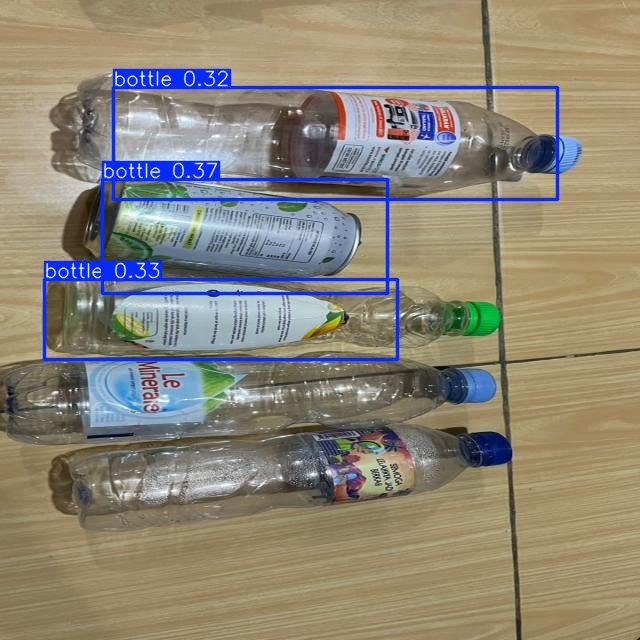

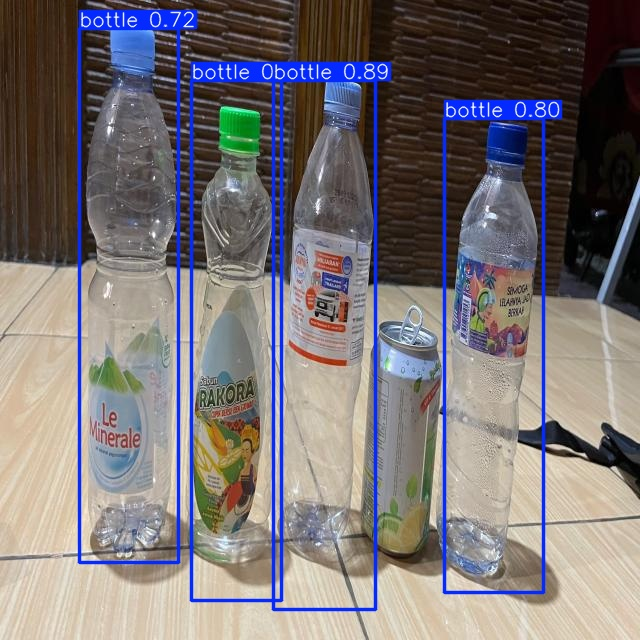

In [ ]:
valid_images = sorted((Path(DATASET_DIR) / "valid" / "images").glob("*"))[:4]
results = best_model.predict(source=[str(p) for p in valid_images], imgsz=IMGSZ, conf=0.25, save=True)
print(f"Prediction images saved to: {results[0].save_dir}")

for p in sorted(Path(results[0].save_dir).glob("*.jpg")):
    display(Image(filename=str(p), width=500))

## 10. Simpan hasil sebelum sesi Colab berakhir

File di Colab hilang saat sesi ditutup atau terputus. Cell di bawah membuat `runs.zip` (berisi `best.pt`,
`results.csv`, dan grafik) lalu men-download-nya ke laptop.

In [ ]:
import shutil

zip_path = shutil.make_archive("runs", "zip", root_dir=".", base_dir="runs")
print(f"Created: {zip_path}")

try:
    from google.colab import files
    files.download(zip_path)
    files.download(str(best_path))
except ImportError:
    print("Not running on Colab: copy the files from this folder directly.")

Created: /content/runs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Inferensi: deteksi pada video untuk demo
!yolo predict model=runs/detect/train/weights/best.pt source=video_demo.mp4 imgsz=640

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

video 1/1 (frame 1/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 6.6ms
video 1/1 (frame 2/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 9.2ms
video 1/1 (frame 3/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 8.9ms
video 1/1 (frame 4/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 8.9ms
video 1/1 (frame 5/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 8.6ms
video 1/1 (frame 6/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 8.5ms
video 1/1 (frame 7/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 8.4ms
video 1/1 (frame 8/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pencil, 8.9ms
video 1/1 (frame 9/1453) /content/video_demo.mp4: 384x640 1 bottle, 1 laptop, 1 pen